# ML Assignment 2 – Classification on the Bank Marketing Dataset

**Name:** Sebastin  
**BITS ID:** 2026ct05199  
**Email:** 2026ct05199@wilp.bits-pilani.ac.in

**Programme:** M.Tech (AIML/DSE) – Machine Learning

**Notebook flow:** 1) Dataset → 2) Preprocessing → 3) Models & metrics → 4) Visualisation → 5) Observations

> Run all cells top to bottom (`Kernel → Restart & Run All`) on BITS Virtual Lab and take your screenshot from that run.

## 0. Setup

In [ ]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             f1_score, matthews_corrcoef, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42   # fixed seed for reproducibility
TEST_SIZE = 0.20    # 80:20 split

# Works whether the notebook sits in the repo root or inside model/
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "model" else cwd
# Use the local dataset if present; otherwise fall back to the GitHub copy (semicolon-separated)
DATA_PATH = PROJECT_ROOT / "bank-full.csv"
DATA_URL = "https://raw.githubusercontent.com/2026CT05199/ML-assignment-2/main/bank-full.csv"
MODEL_DIR = PROJECT_ROOT / "model"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODEL_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
print("Project root:", PROJECT_ROOT)

Project root: /content


## 1. Dataset choice

**Dataset:** Bank Marketing (`bank-full.csv`), UCI Machine Learning Repository – <https://archive.ics.uci.edu/dataset/222/bank+marketing>

**Why this dataset:** It describes a real business problem: a bank wants to know which customers are likely to subscribe to a term deposit, so it can focus its phone campaign instead of calling everyone. It is large (45,211 rows) and has 16 features, a mix of 7 numeric and 9 categorical ones, which suits all five models. It is also realistic and not "clean": only about 12 % of clients subscribe, and some missing values are hidden as the text `"unknown"`, so choosing sensible preprocessing and metrics actually matters.

**Target variable:** `y` – whether the client subscribed to a term deposit (`yes` / `no`).

In [ ]:
df = pd.read_csv(DATA_PATH if DATA_PATH.exists() else DATA_URL, sep=";")
print("Shape (rows, columns):", df.shape)
print(f"Features (excluding target): {df.shape[1] - 1}")
df.head()

Shape (rows, columns): (45211, 17)
Features (excluding target): 16


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
numeric_cols = df.drop(columns="y").select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.drop(columns="y").select_dtypes(exclude=np.number).columns.tolist()
print(f"Numeric features ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")
df.dtypes.to_frame("dtype")

Numeric features (7): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical features (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


,dtype
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


### Class distribution (imbalance check)

     count  percent
y                  
no   39922     88.3
yes   5289     11.7

Imbalance ratio (no : yes) = 7.55 : 1


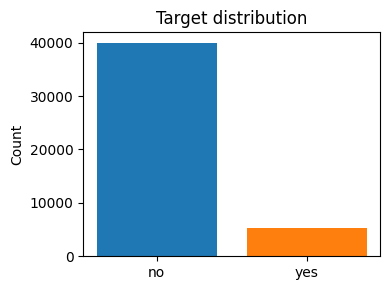

In [ ]:
counts = df["y"].value_counts()
pct = df["y"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(2)}))
print(f"\nImbalance ratio (no : yes) = {counts['no'] / counts['yes']:.2f} : 1")

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(counts.index, counts.values, color=["tab:blue", "tab:orange"])
ax.set_title("Target distribution"); ax.set_ylabel("Count")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150); plt.show()

**Observation:** The target is strongly imbalanced: 39,922 clients (88.30 %) said "no" and only 5,289 (11.70 %) said "yes", a ratio of 7.55 : 1. A model that always predicts "no" would therefore already reach about 88 % accuracy while finding zero subscribers, so accuracy alone says very little here. kNN and Random Forest score 0.888 and Logistic Regression only 0.755, yet Logistic Regression finds the most real subscribers. For this reason Precision, Recall, F1, AUC and MCC are used to compare the models, with F1, AUC and MCC given the most weight.

## 2. Data preprocessing

### 2.1 Missing values

In this dataset missing values are encoded as the text `"unknown"`, so `isna()` finds none. Meaning differs per column:

- `job`, `education` → genuinely missing → convert to `NaN` and impute (inside the pipeline).
- `contact`, `poutcome` → `"unknown"` is informative (e.g. no previous campaign outcome) → keep as its own category.
- `pdays = -1` means the client was **not previously contacted** (a sentinel, not a real number of days).

In [ ]:
print("isna() count (misleading):", int(df.isna().sum().sum()))

unknown_counts = (df.drop(columns="y") == "unknown").sum()
unknown_counts = unknown_counts[unknown_counts > 0]
print("\n'unknown' values per column:")
print(pd.DataFrame({"count": unknown_counts, "percent": (unknown_counts / len(df) * 100).round(2)}))

print("\npdays == -1 (never contacted before):", int((df["pdays"] == -1).sum()),
      f"({(df['pdays'] == -1).mean() * 100:.1f}%)")

isna() count (misleading): 0

'unknown' values per column:
           count  percent
job          288     0.64
education   1857     4.11
contact    13020    28.80
poutcome   36959    81.75

pdays == -1 (never contacted before): 36954 (81.7%)


In [ ]:
TRUE_MISSING_COLS = ["job", "education"]
df[TRUE_MISSING_COLS] = df[TRUE_MISSING_COLS].replace("unknown", np.nan)
print(df[TRUE_MISSING_COLS].isna().sum())

job           288
education    1857
dtype: int64


### 2.2 Duplicates

In [ ]:
n_dup = int(df.duplicated().sum())
print("Exact duplicate rows:", n_dup)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Exact duplicate rows: 0
Shape after removing duplicates: (45211, 17)


### 2.3 Feature engineering and leakage control

- `duration` (last call length) is only known **after** the call, so it would leak the outcome into a pre-call prediction. It is dropped.
- `pdays = -1` is replaced by a binary flag `previously_contacted`, and `pdays` becomes 0 for those clients so the sentinel does not distort scaling.

In [ ]:
df["previously_contacted"] = (df["pdays"] != -1).astype(int)
df["pdays"] = df["pdays"].replace(-1, 0)

X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1}).astype(int)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
print(f"Numeric ({len(numeric_features)}): {numeric_features}")
print(f"Categorical ({len(categorical_features)}): {categorical_features}")

Numeric (7): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']
Categorical (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


### 2.4 Stratified 80:20 train-test split (fixed seed)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate – train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))

# Save test data required by the brief
test_data = X_test.copy()
test_data["y"] = y_test.map({0: "no", 1: "yes"})
test_data.to_csv(PROJECT_ROOT / "test_data.csv", index=False)
print("Saved test_data.csv with", len(test_data), "rows")

Train: (36168, 16) | Test: (9043, 16)
Positive rate – train: 0.1170 | test: 0.1170
Saved test_data.csv with 9043 rows


### 2.5 Encoding, imputation and scaling (fitted on training data only)

All transformers live inside a `Pipeline`, so `fit` sees only `X_train`; the test set is only transformed.

- Numeric: median imputation (+ `StandardScaler` for models sensitive to scale: Logistic Regression, kNN, Naive Bayes).
- Categorical: most-frequent imputation + one-hot encoding (`handle_unknown="ignore"`).
- Tree-based models do not need scaling.

In [ ]:
def make_preprocessor(scale_numeric):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    cat_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), numeric_features),
        ("cat", Pipeline(cat_steps), categorical_features),
    ])

## 3. Models and evaluation metrics

In [ ]:
# (classifier, needs_scaling)
model_specs = {
    "Logistic Regression": (LogisticRegression(class_weight="balanced", max_iter=1000,
                                               random_state=RANDOM_STATE), True),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", max_depth=10,
                                             min_samples_leaf=5, random_state=RANDOM_STATE), False),
    "kNN": (KNeighborsClassifier(n_neighbors=7, weights="distance"), True),
    "Naive Bayes": (GaussianNB(), True),
    "Random Forest (Ensemble)": (RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                        min_samples_leaf=2, n_jobs=-1,
                                                        random_state=RANDOM_STATE), False),
}

models = {name: Pipeline([("preprocessor", make_preprocessor(scale)), ("classifier", clf)])
          for name, (clf, scale) in model_specs.items()}
list(models)

['Logistic Regression',
 'Decision Tree',
 'kNN',
 'Naive Bayes',
 'Random Forest (Ensemble)']

**Model configuration and reasons**

| Model | Key settings | Why |
| --- | --- | --- |
| Logistic Regression | `class_weight="balanced"`, `max_iter=1000`, scaled inputs | Balanced weights offset the 7.55 : 1 imbalance; more iterations ensure convergence; scaling suits a linear model. |
| Decision Tree | `class_weight="balanced"`, `max_depth=10`, `min_samples_leaf=5`, no scaling | Depth and leaf limits reduce overfitting; trees do not need scaling. |
| kNN | `n_neighbors=7`, `weights="distance"`, scaled inputs | An odd k avoids ties, distance weighting favours closer neighbours, and scaling is needed because kNN is distance-based. |
| Naive Bayes | `GaussianNB()` defaults, scaled inputs | Simple probabilistic baseline. |
| Random Forest | 300 trees, `class_weight="balanced_subsample"`, `min_samples_leaf=2`, no scaling | Many trees reduce variance; subsample class weights handle the imbalance in each tree. |

In [ ]:
rows, fitted, preds, scores = [], {}, {}, {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    fitted[name], preds[name], scores[name] = pipe, pred, proba
    rows.append({
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, proba),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, pred),
    })
    joblib.dump(pipe, MODEL_DIR / (name.split(" (")[0].lower().replace(" ", "_") + ".joblib"))
    print("Trained and saved:", name)

results = pd.DataFrame(rows).set_index("ML Model Name")
results.to_csv(OUTPUT_DIR / "results.csv", float_format="%.4f")
results.round(4)

Trained and saved: Logistic Regression
Trained and saved: Decision Tree
Trained and saved: kNN
Trained and saved: Naive Bayes
Trained and saved: Random Forest (Ensemble)


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7548,0.7722,0.2662,0.6238,0.3732,0.2853
Decision Tree,0.8225,0.7502,0.3427,0.5633,0.4262,0.3427
kNN,0.8881,0.7153,0.5581,0.2089,0.3040,0.2937
Naive Bayes,0.8367,0.7502,0.3509,0.4660,0.4003,0.3121
Random Forest (Ensemble),0.8880,0.8012,0.5286,0.3932,0.4509,0.3954


**Number of models:** 5, the five required models from the brief (Logistic Regression, Decision Tree, kNN, Naive Bayes, Random Forest). The table above holds the measured results and is saved as `outputs/results.csv`.

## 4. Visualisation

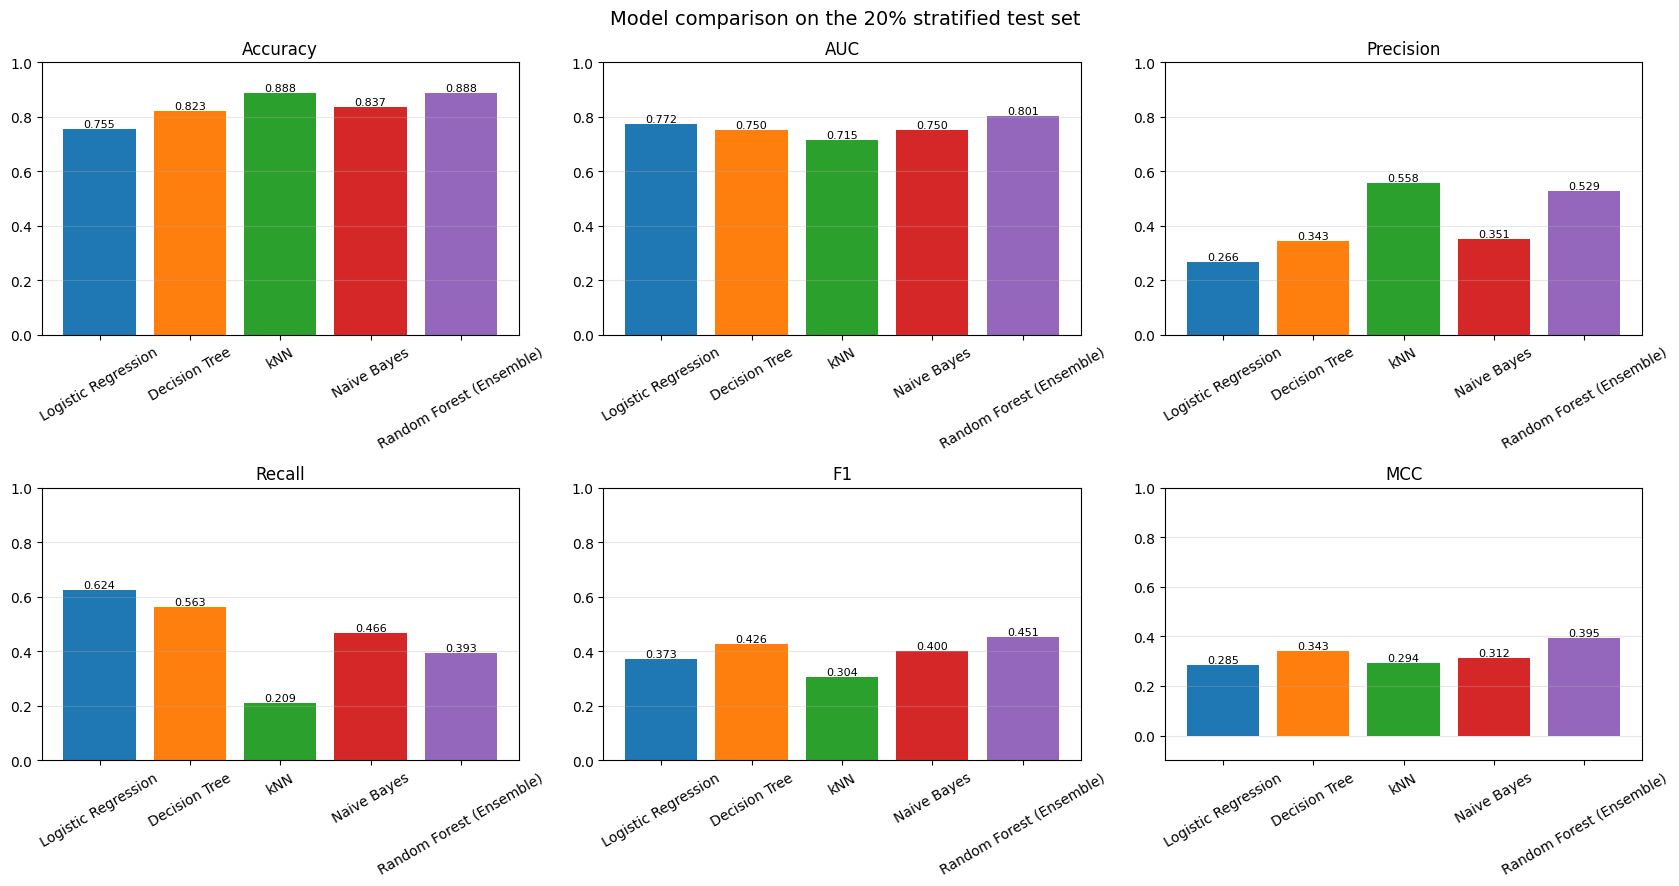

In [ ]:
metrics = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
colors = plt.get_cmap("tab10").colors
for ax, m in zip(axes.flat, metrics):
    bars = ax.bar(results.index, results[m], color=colors[:len(results)])
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
    ax.set_title(m); ax.set_ylim(-0.1 if m == "MCC" else 0, 1)
    ax.tick_params(axis="x", rotation=30); ax.grid(axis="y", alpha=0.3)
fig.suptitle("Model comparison on the 20% stratified test set", fontsize=14)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "metric_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

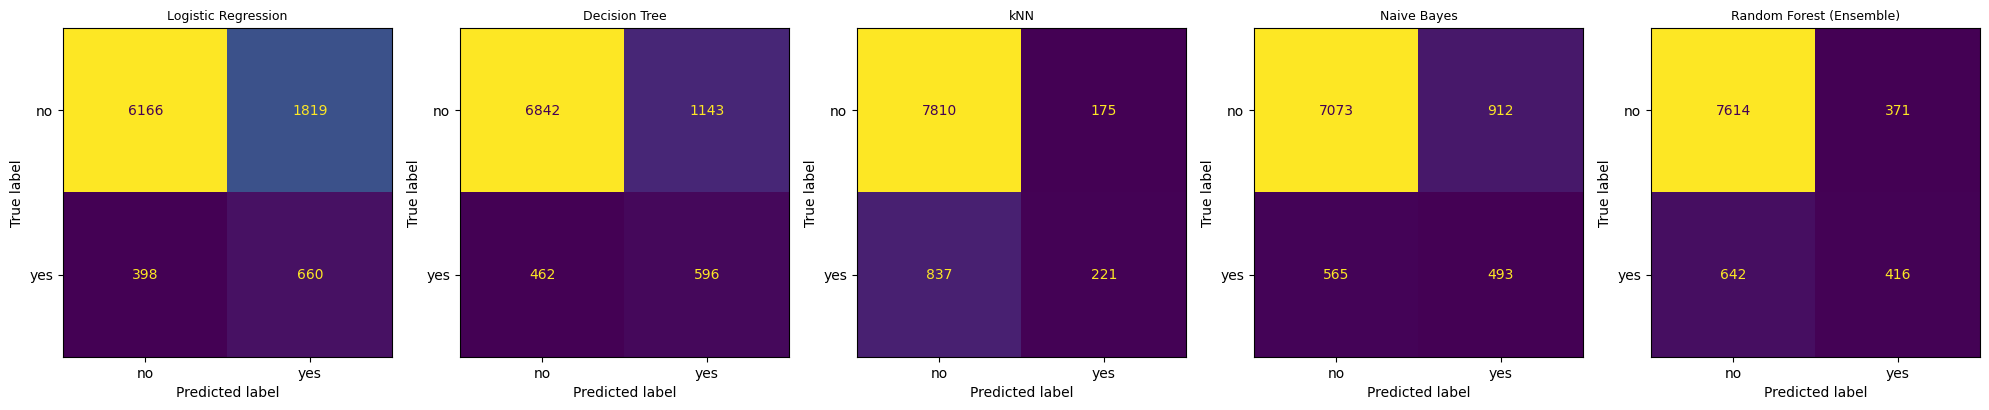

In [ ]:
fig, axes = plt.subplots(1, len(fitted), figsize=(4 * len(fitted), 4))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["no", "yes"],
                                            colorbar=False, ax=ax)
    ax.set_title(name, fontsize=9)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150); plt.show()

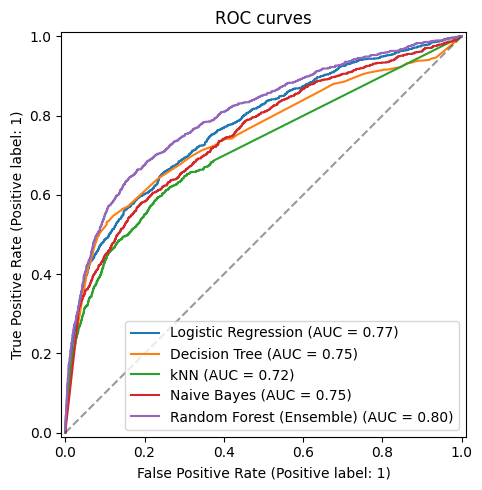

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, s in scores.items():
    RocCurveDisplay.from_predictions(y_test, s, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC curves"); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=150); plt.show()

## 5. Observations

All numbers below come from the results table and graphs above (test set: 9,043 rows, of which 1,058 are real subscribers).

| ML Model Name | Observation about model performance |
| --- | --- |
| Logistic Regression | Best recall (0.624): it finds 660 of the 1,058 real subscribers, because `class_weight="balanced"` pushes it to predict "yes" more often. The price is the lowest precision (0.266) with 1,819 false alarms, so accuracy (0.755) and MCC (0.285) are the lowest of all five. Its AUC (0.772) is second best, so it ranks customers well; the weakness is the default 0.5 cut-off, not the model itself. |
| Decision Tree | A middle-of-the-road model: accuracy 0.823, precision 0.343, recall 0.563, F1 0.426 and MCC 0.343, second best on both F1 and MCC. Limiting depth to 10 and leaf size to 5 kept it from overfitting, but its AUC (0.750) is lower than the forest's because a single tree gives coarse probability scores. |
| kNN | Highest accuracy (0.888) and precision (0.558), but this is misleading: recall is only 0.209 (221 of 1,058 subscribers found, 837 missed) and it predicts "yes" only about 400 times. Its accuracy is barely above the 88.3 % "always no" baseline. It also has the lowest AUC (0.715) and F1 (0.304), since it has no class weighting and distances get diluted by many one-hot columns. |
| Naive Bayes | Accuracy 0.837, precision 0.351, recall 0.466, F1 0.400, MCC 0.312 and AUC 0.750, so it sits in the middle for every metric. It finds more subscribers than kNN and the forest (493 vs 221 and 416) but with 912 false positives. Its independence assumption is probably strained by related features such as `poutcome`, `pdays`, `previous` and `previously_contacted`. |
| Random Forest (Ensemble) | Best overall balance: highest AUC (0.801), F1 (0.451) and MCC (0.395), with accuracy (0.888) essentially tied with kNN. Precision is 0.529 and recall 0.393 (416 true positives, 371 false positives), so it misses 642 subscribers, but it is far more reliable than the other models when it does say "yes". Averaging many trees reduces the variance of a single tree. |
| **Overall winner for your dataset?** | **Random Forest.** It ranks first on AUC, F1 and MCC, the three metrics that account for the 7.55:1 imbalance, while its accuracy is within 0.0001 of the top score. kNN wins on accuracy and precision only because it rarely predicts "yes". If the bank cared mostly about reaching as many likely subscribers as possible, Logistic Regression or the Decision Tree (higher recall) could be preferred, or the forest's threshold could be lowered. |

In [ ]:
# Helper only: rank models per metric to guide your own observations
print(results.rank(ascending=False).astype(int))
print("\nHighest MCC:", results["MCC"].idxmax(), "| Highest AUC:", results["AUC"].idxmax())

                          Accuracy  AUC  Precision  Recall  F1  MCC
ML Model Name                                                      
Logistic Regression              5    2          5       1   4    5
Decision Tree                    4    3          4       2   2    2
kNN                              1    5          1       5   5    4
Naive Bayes                      3    4          3       3   3    3
Random Forest (Ensemble)         2    1          2       4   1    1

Highest MCC: Random Forest (Ensemble) | Highest AUC: Random Forest (Ensemble)


## BITS Virtual Lab execution screenshots

Screenshots captured during the BITS Virtual Lab session. The remote desktop URL strip is obscured to protect the session token; the original screenshot files are unchanged.


### 10:59:32 PM — Notebook title and setup

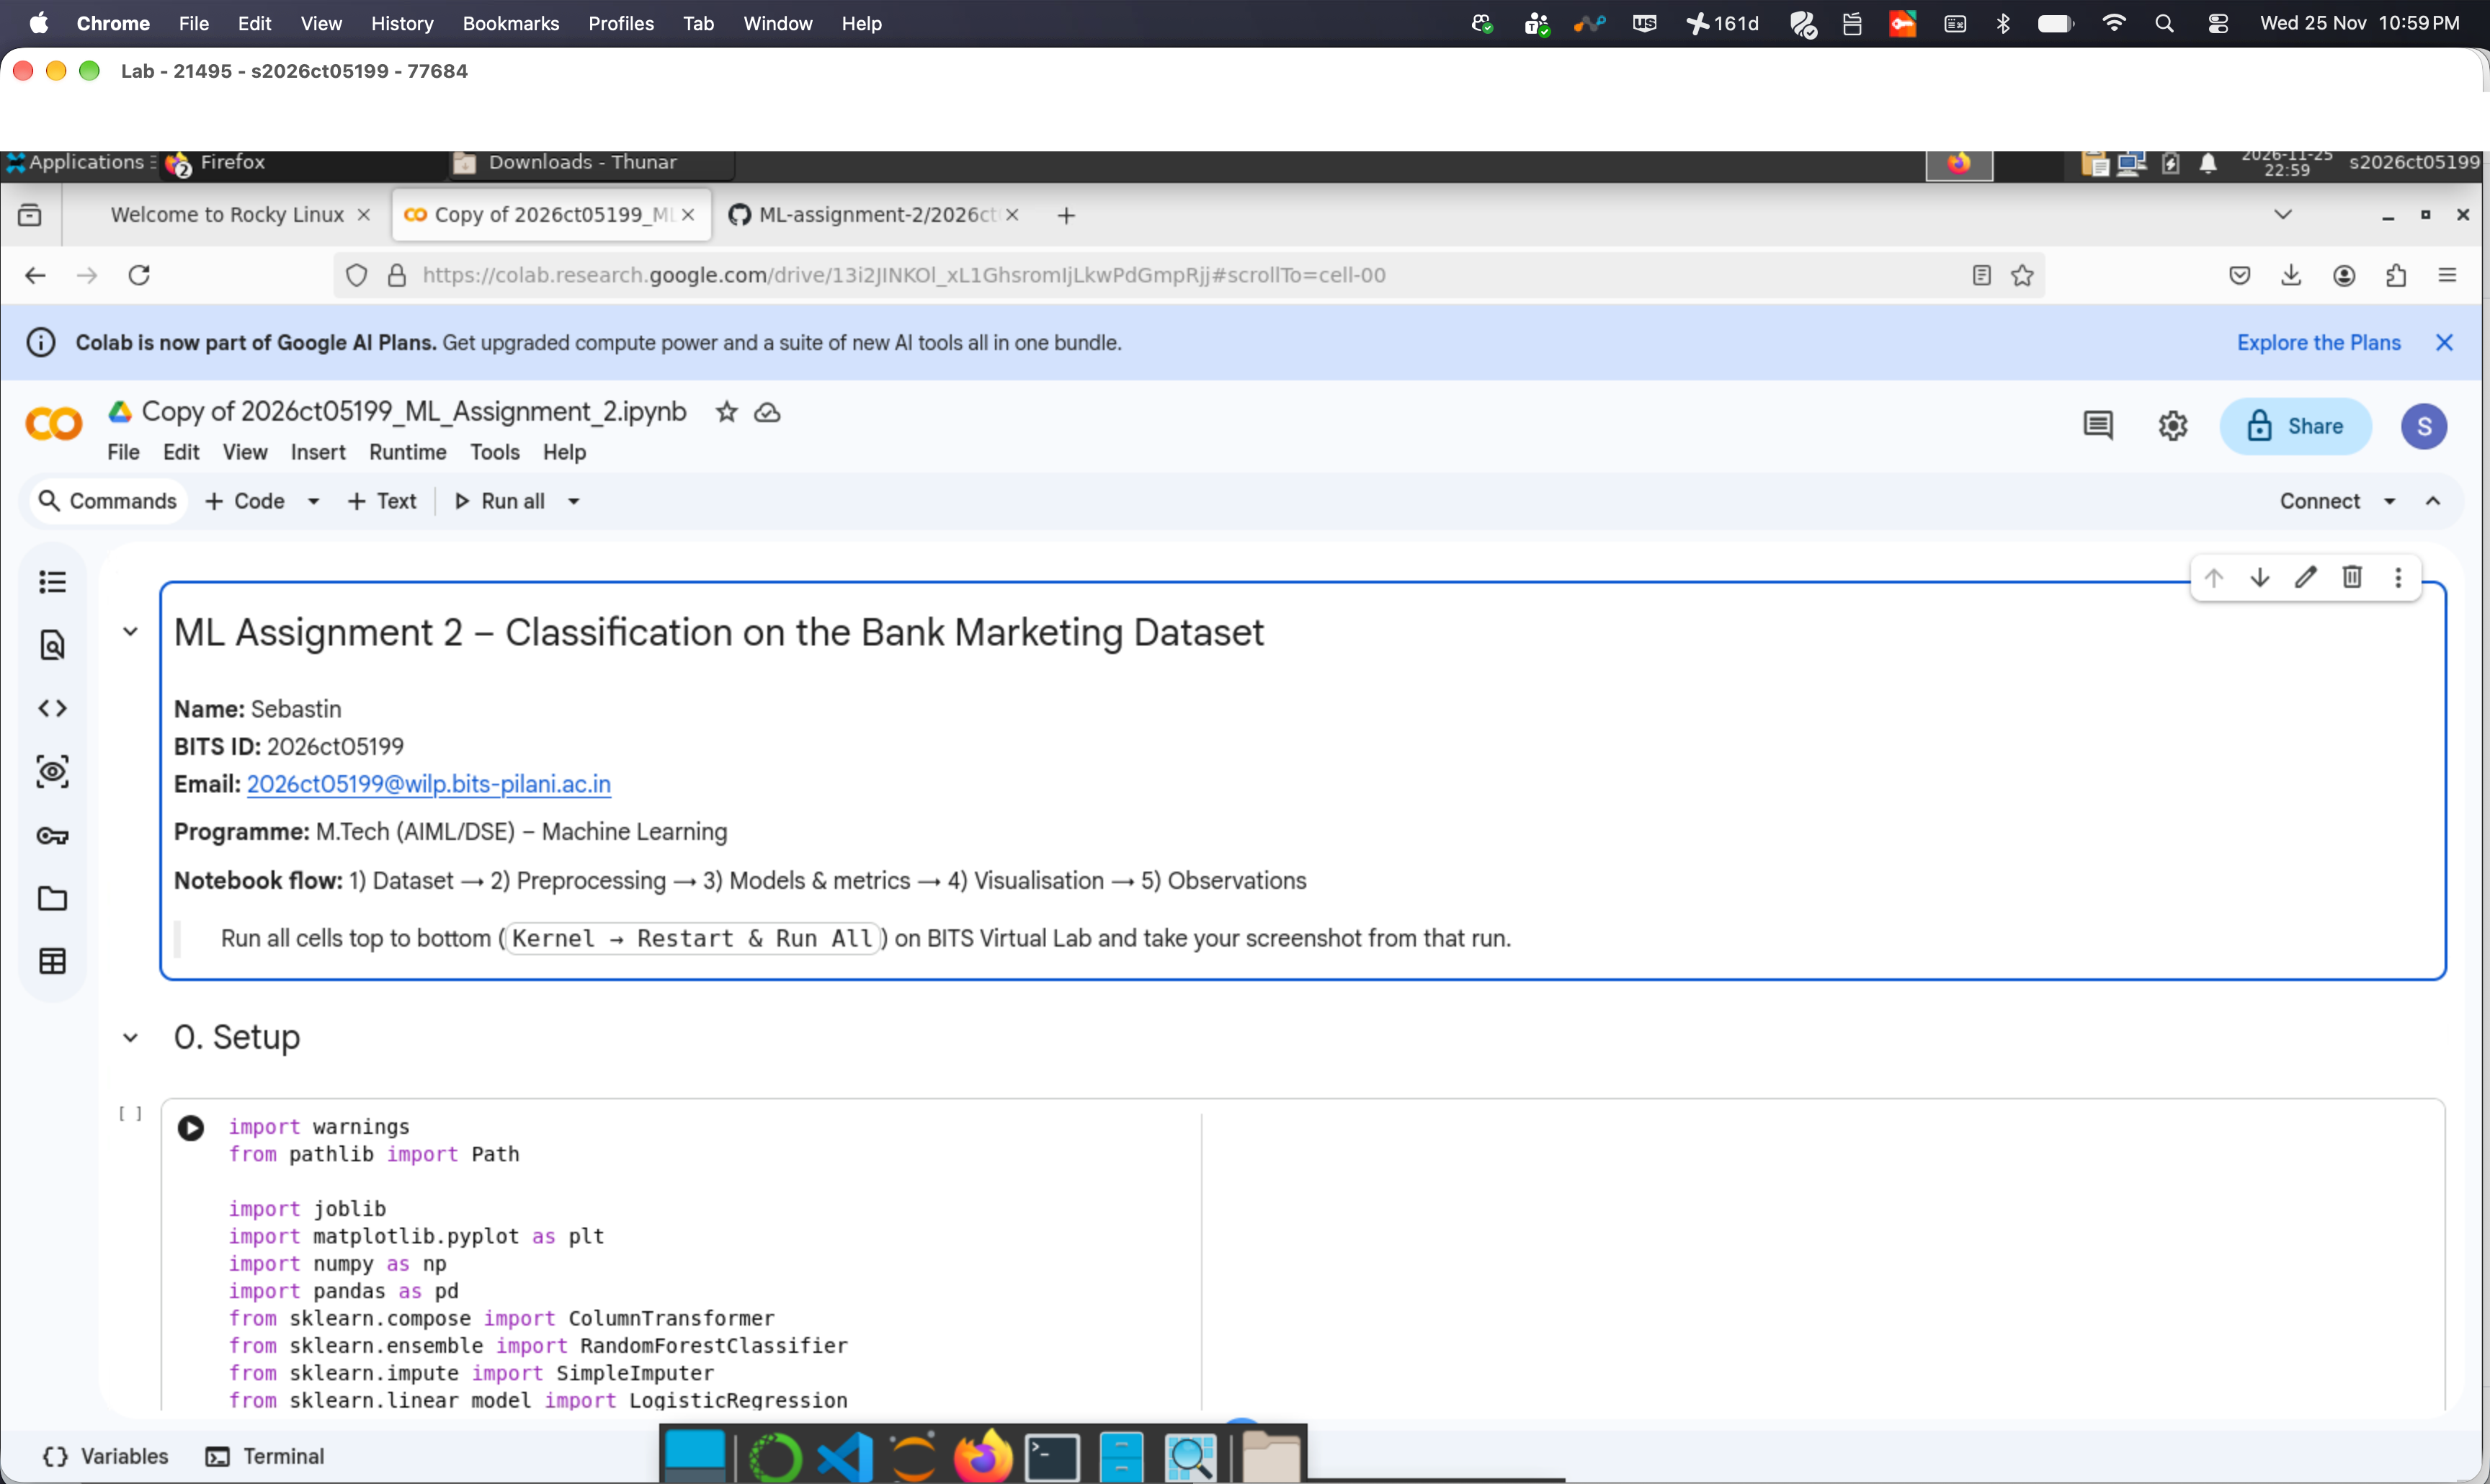

### 10:59:22 PM — Dataset loading and dimensions

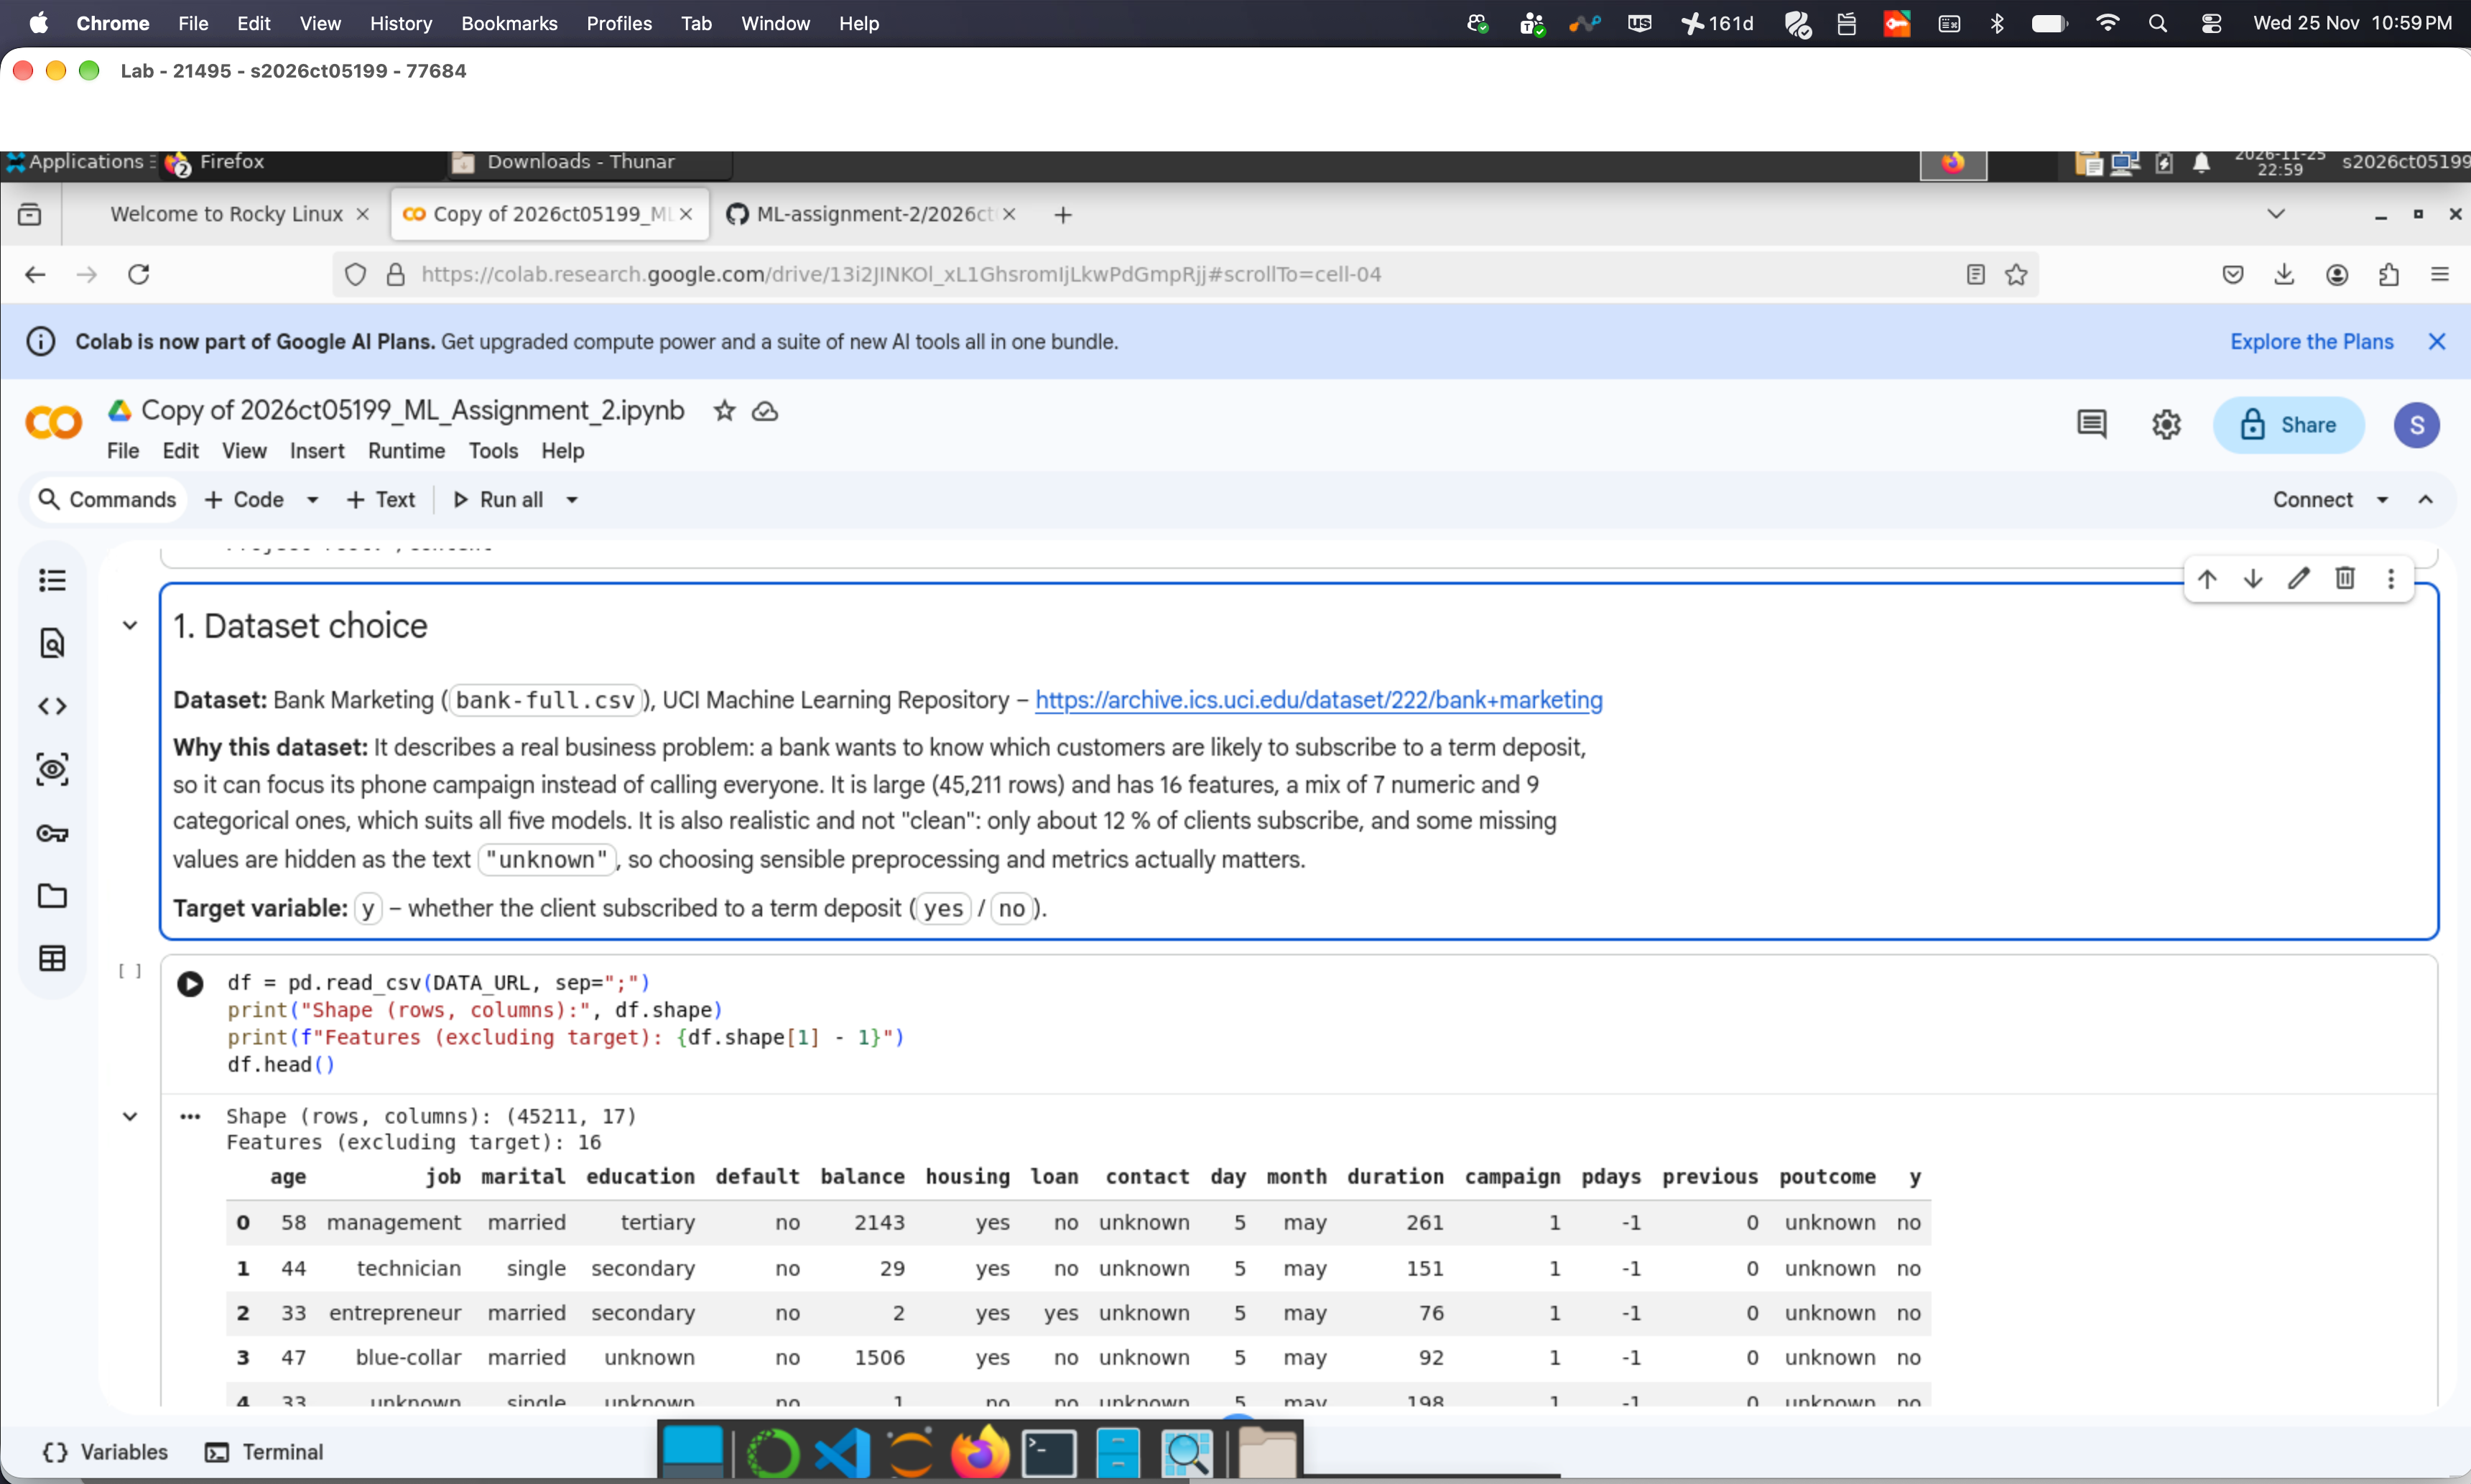

### 10:58:50 PM — Model results table

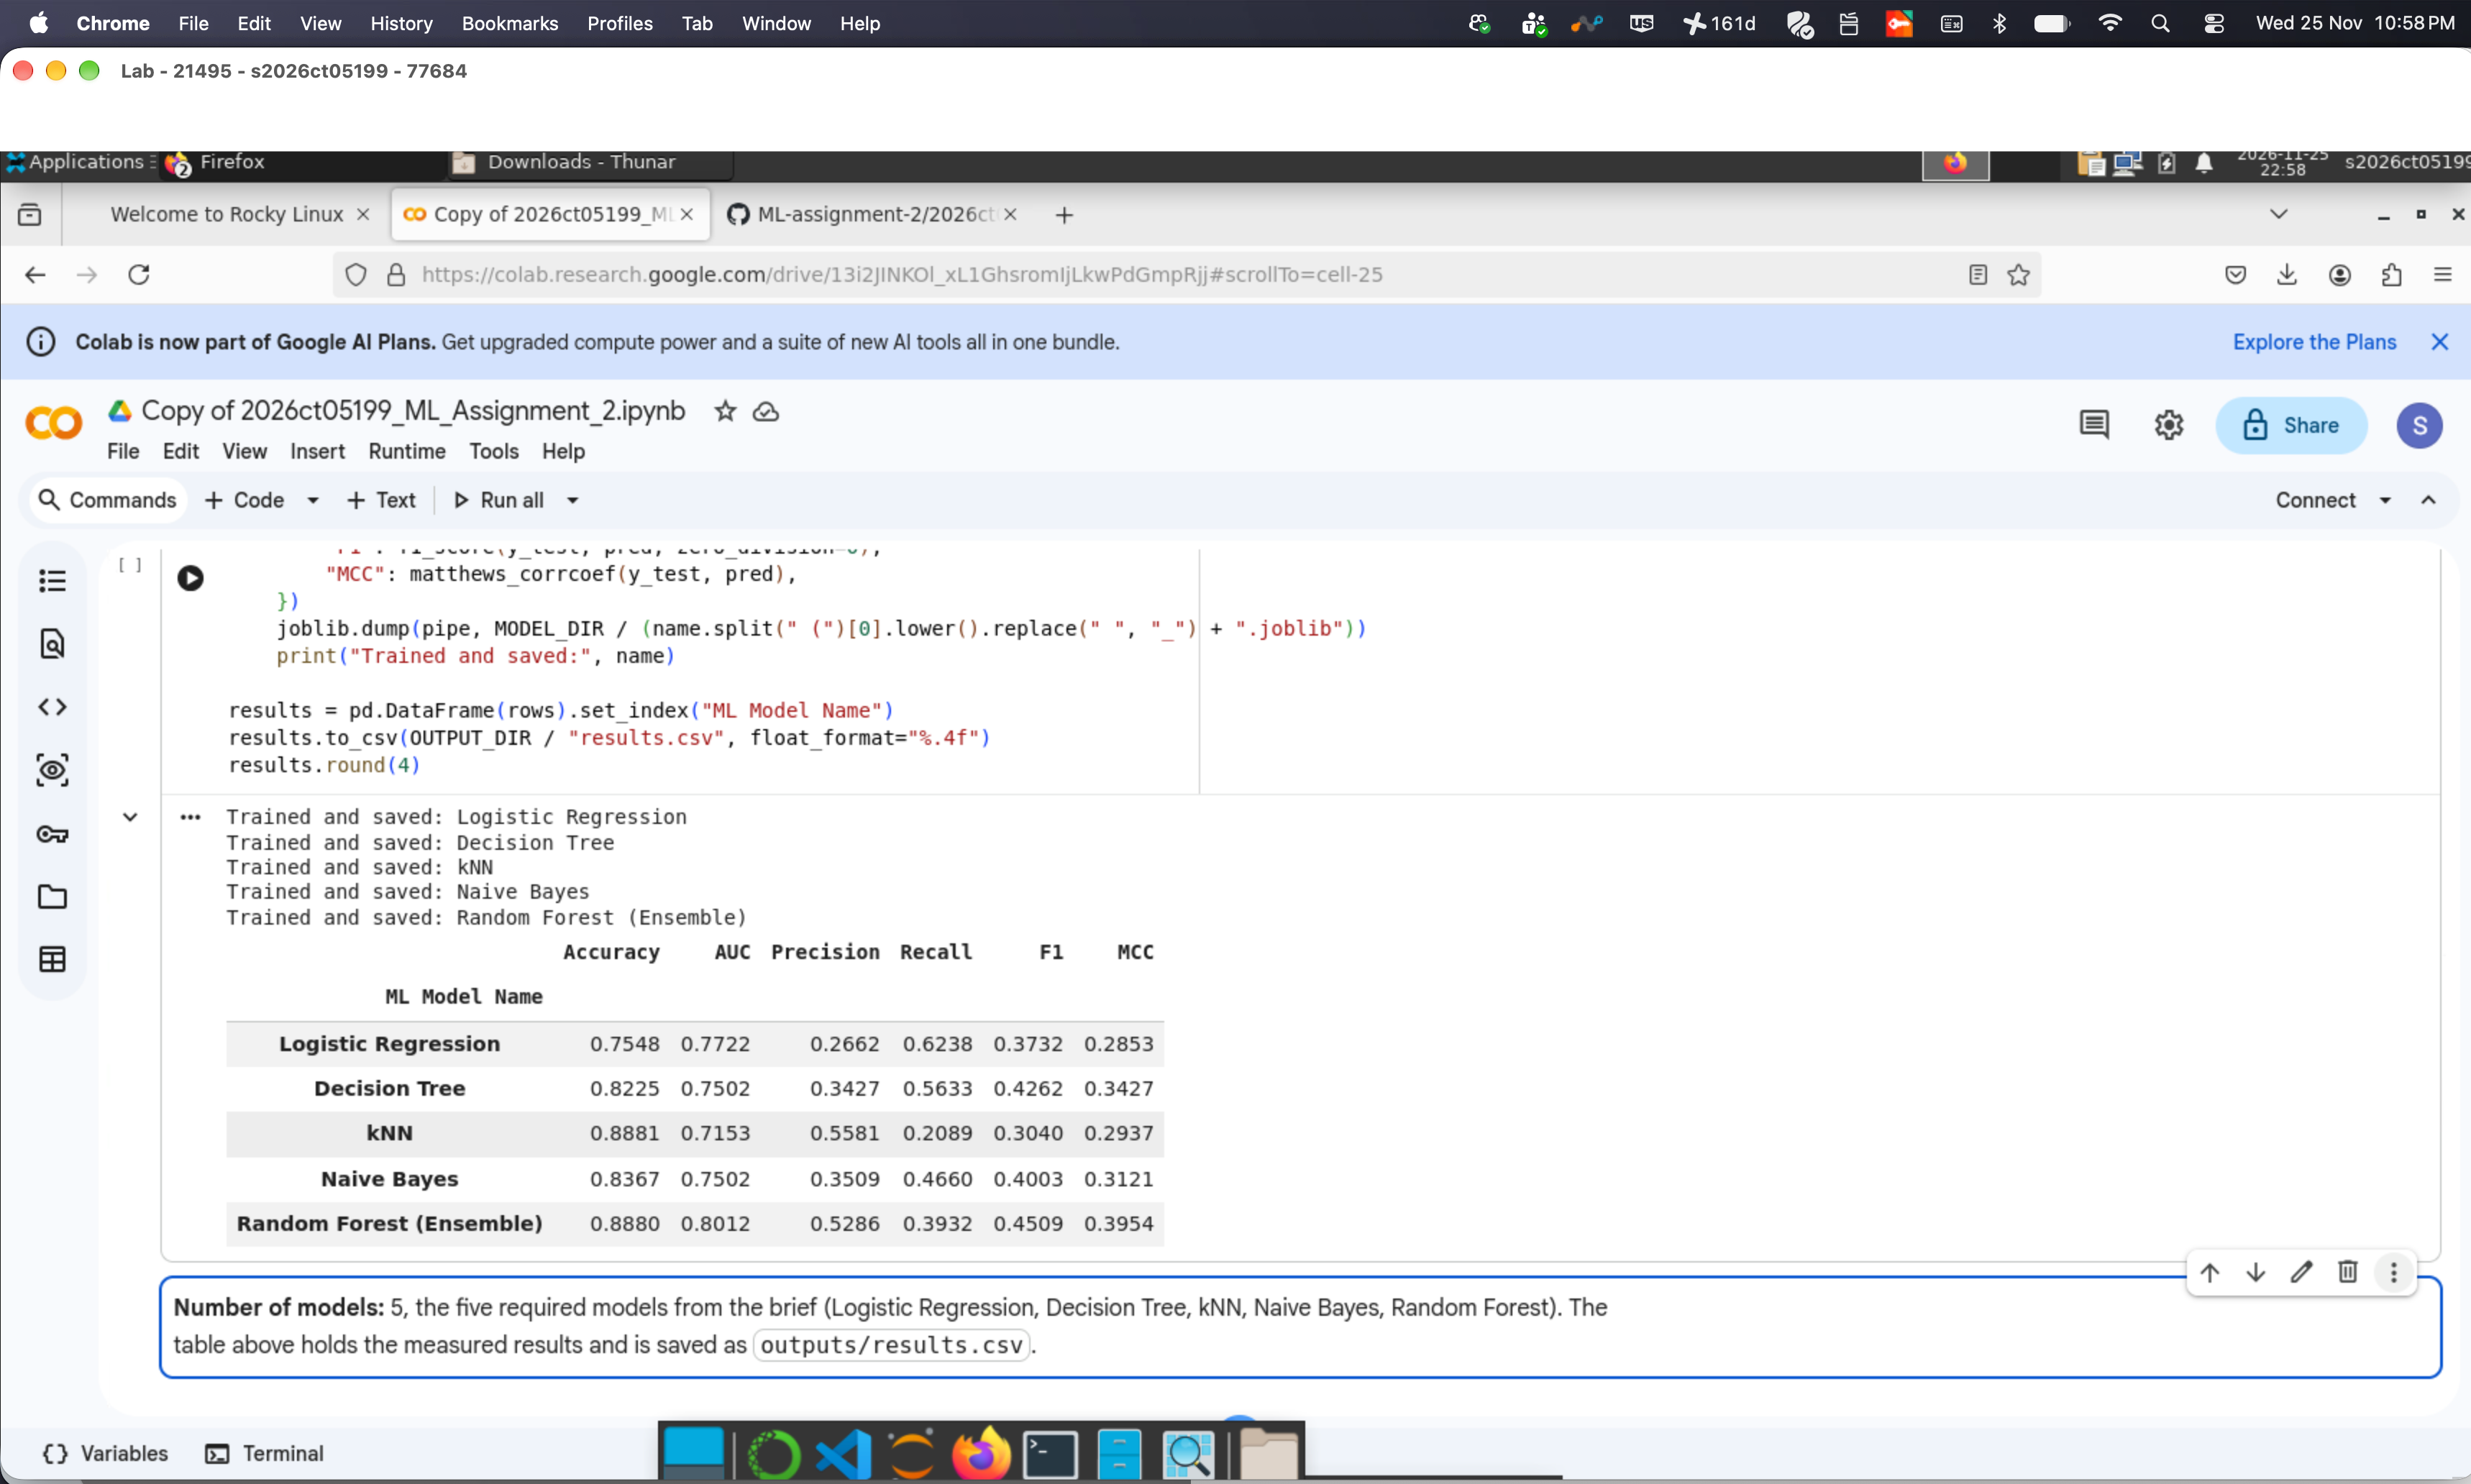

### 10:58:36 PM — Evaluation metric visualizations

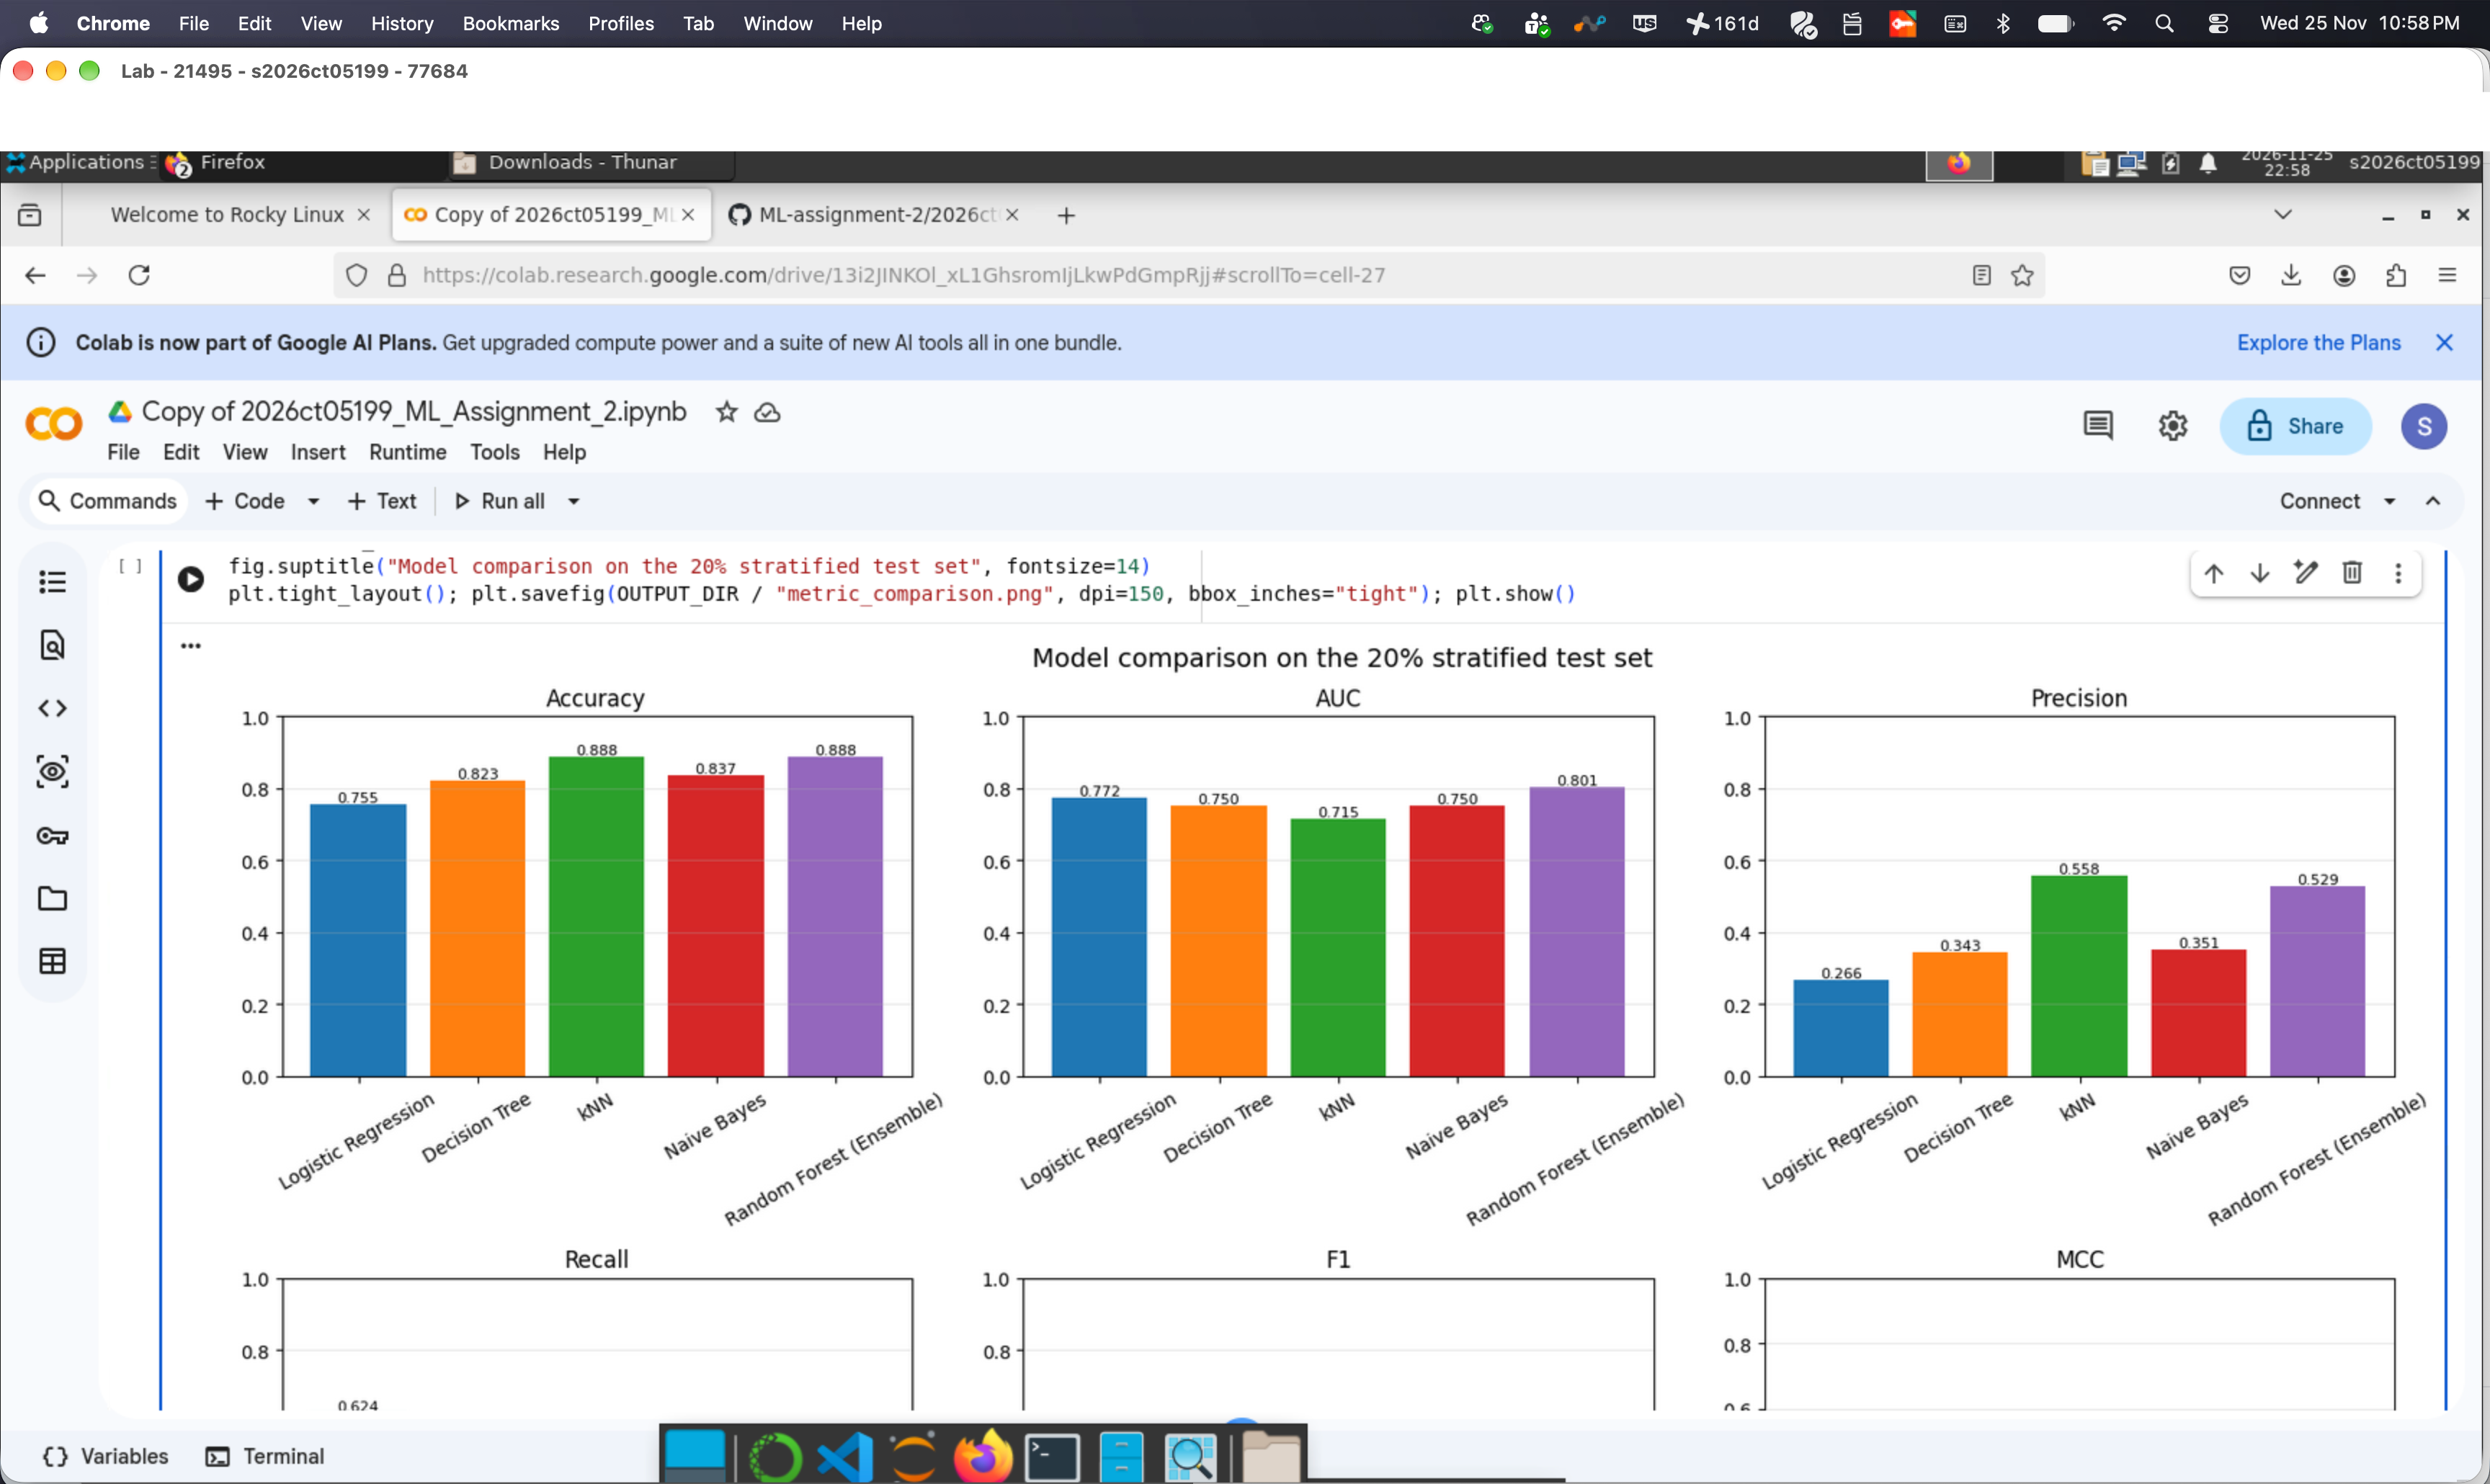

### 10:58:13 PM — Confusion matrices and ROC section

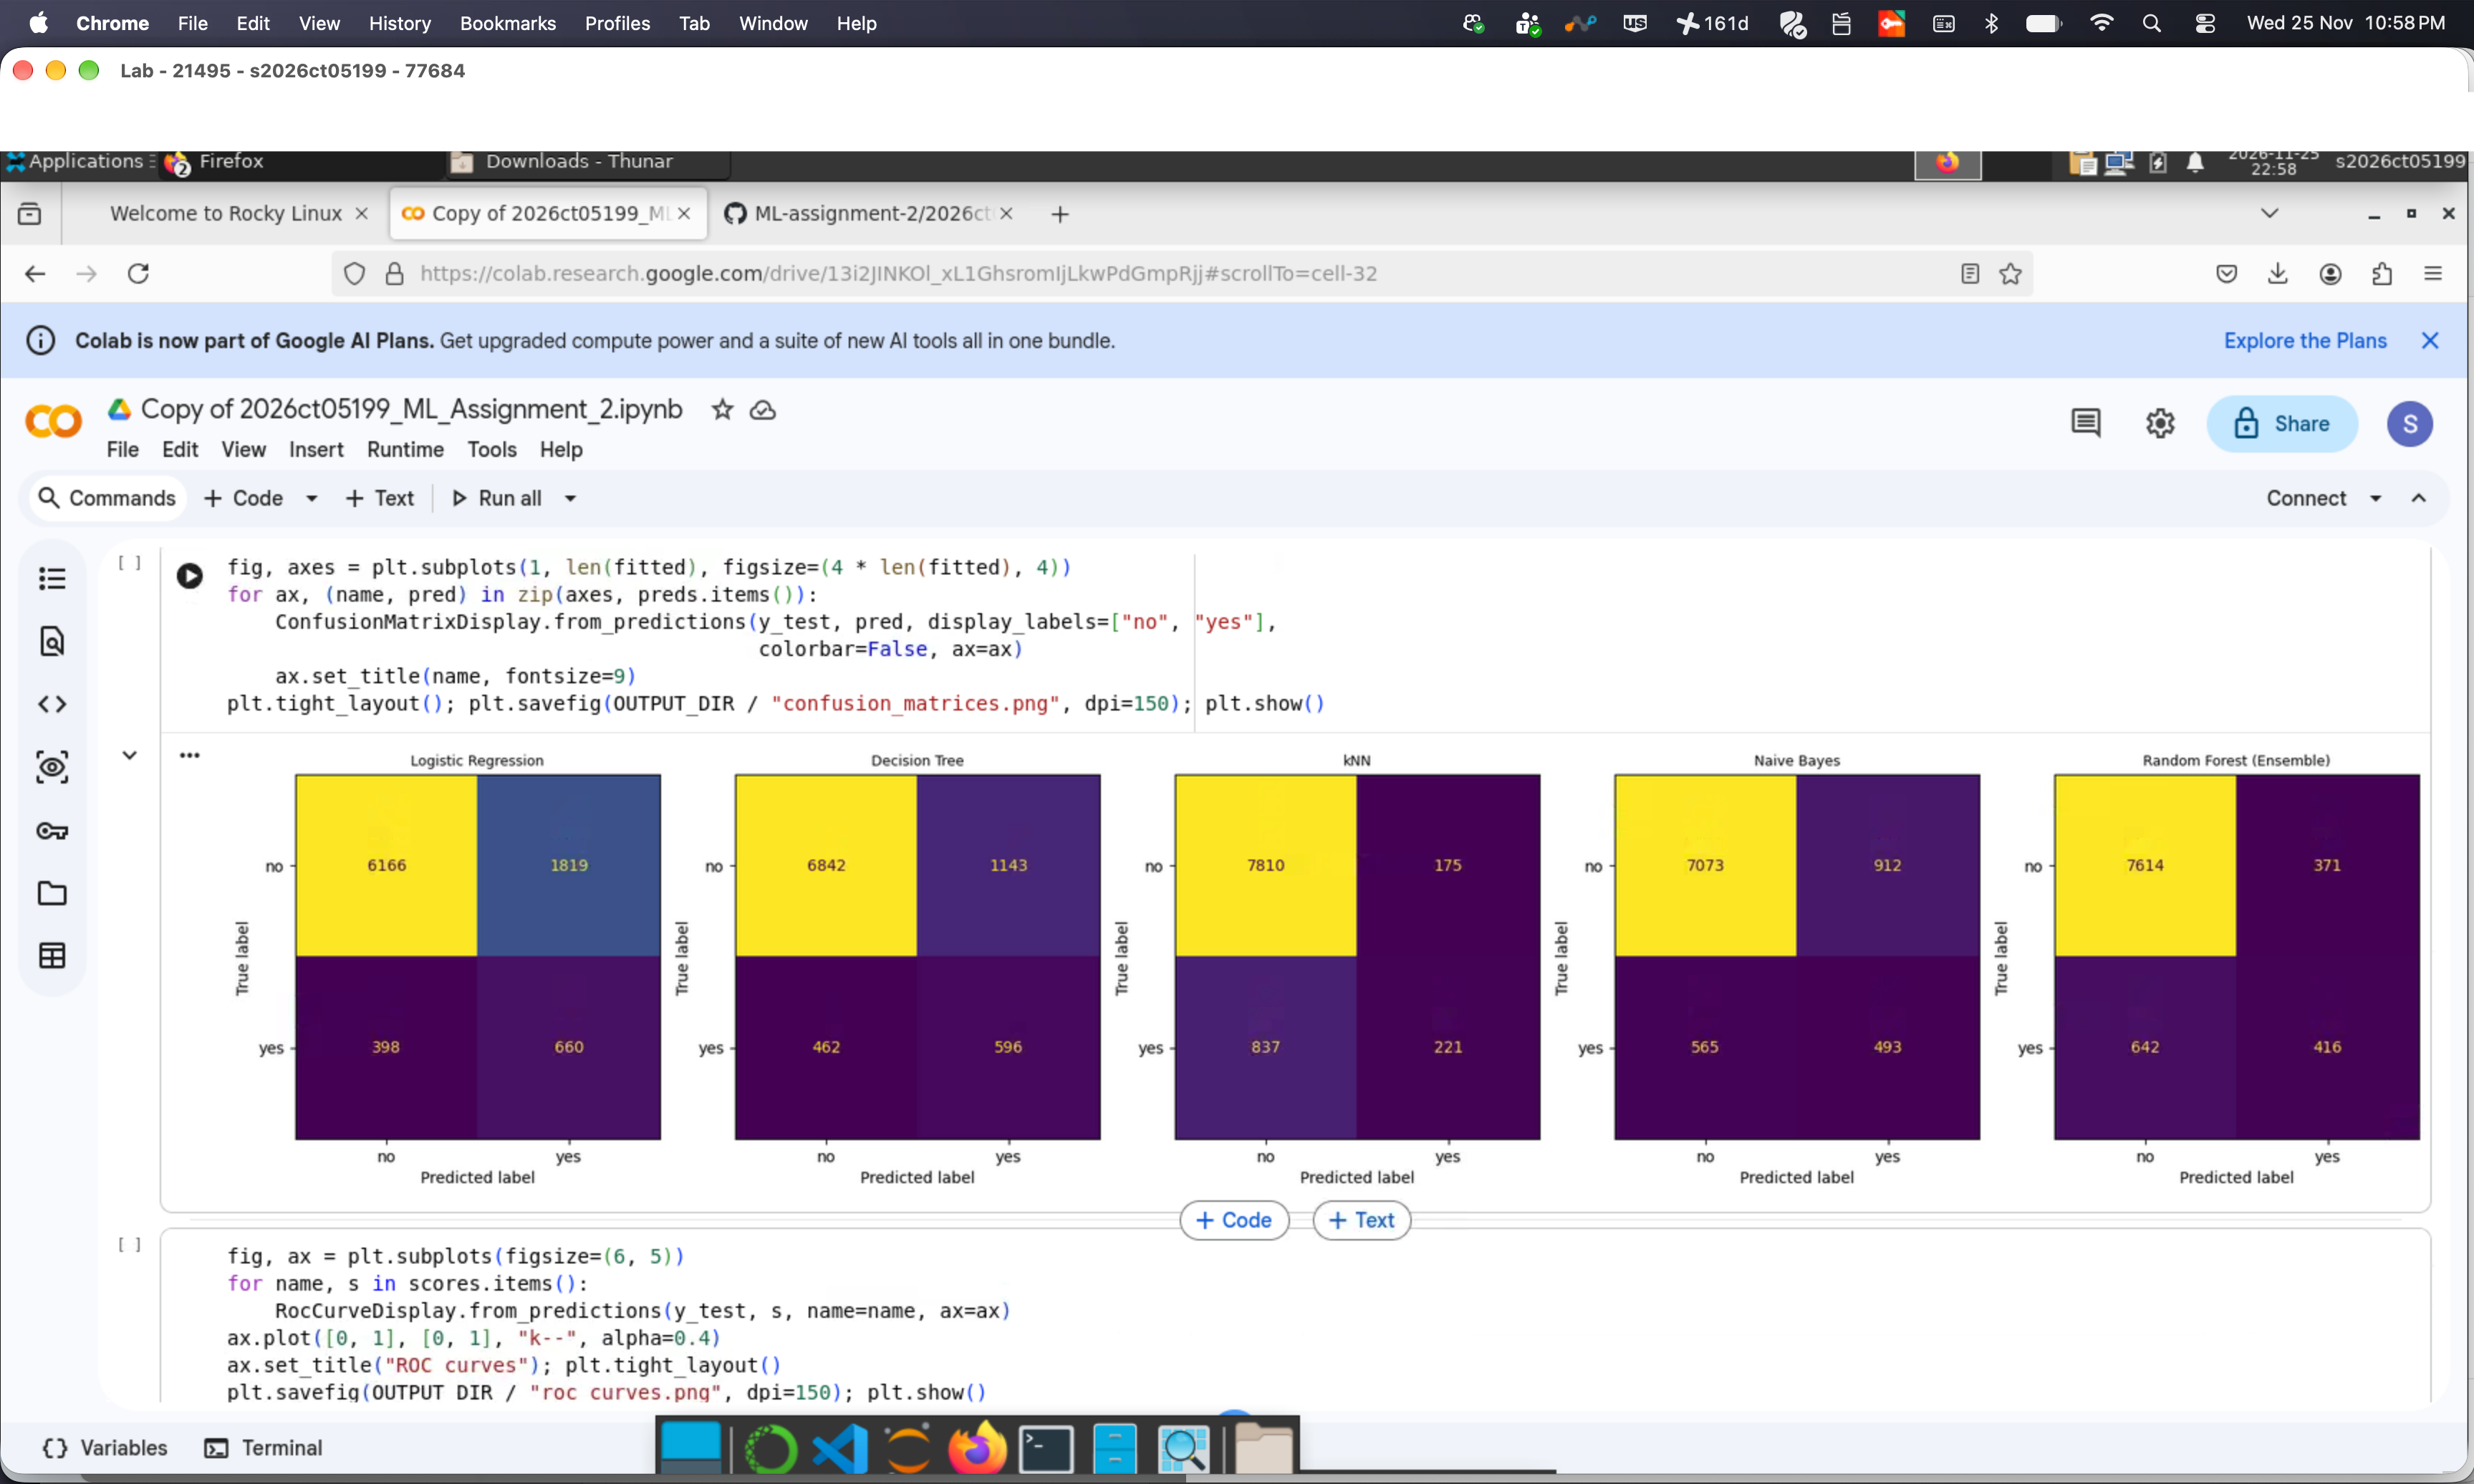

### 10:57:45 PM — ROC plot and model observations

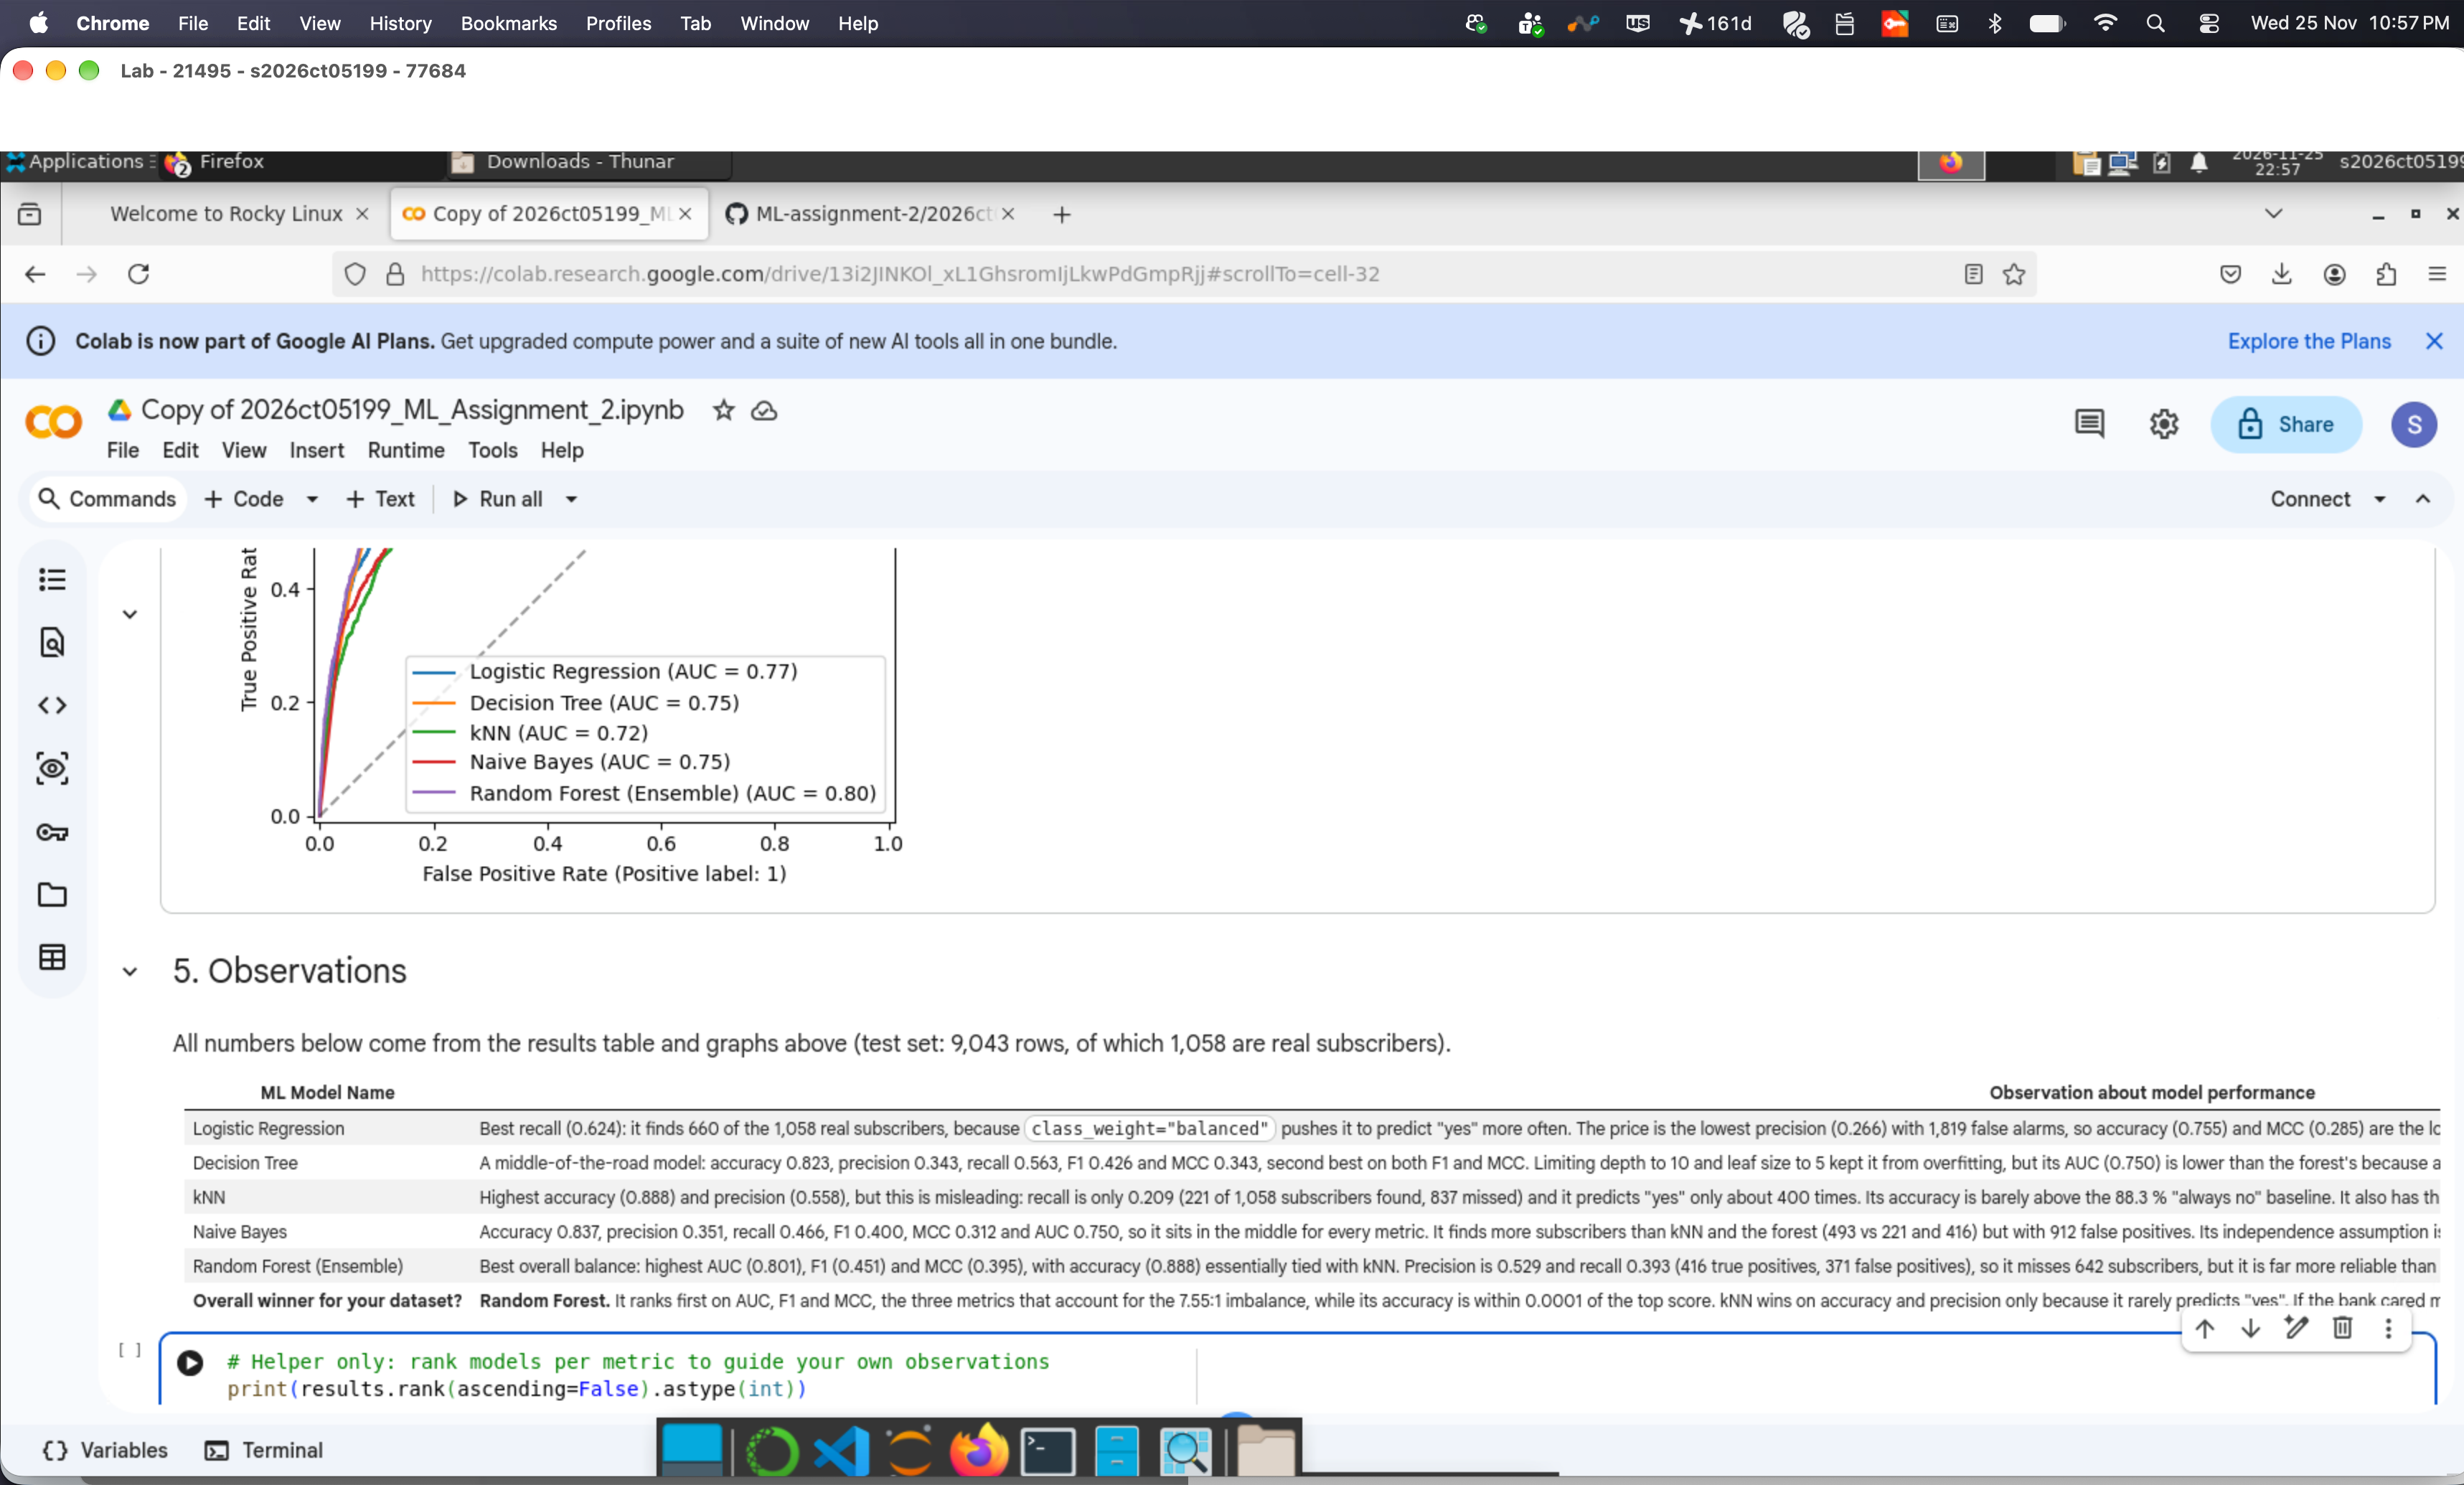